# Main

## Figure 2 – Annual and Cumulative Publication Trends (2002-2025). 

`annual_and_cumulative_publication_trends.png` as chart saved.


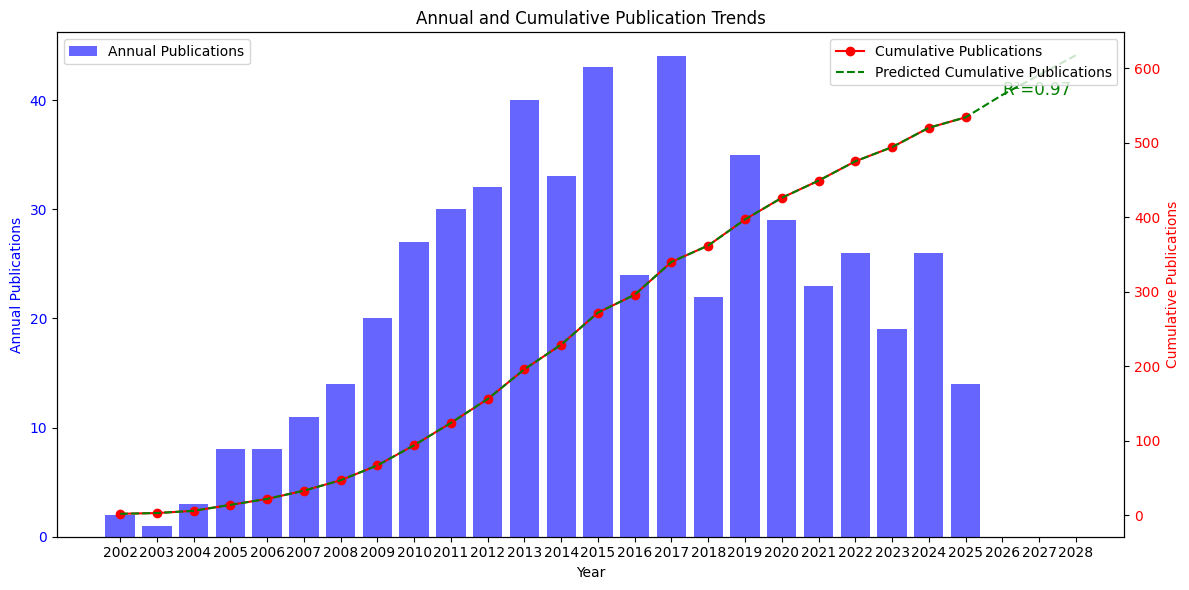

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_dataset import DATASET

df = DATASET()


df = df[df['year'].str.strip() != '']  # remove rows with blank strings

# Convert year to integer
df['year'] = df['year'].astype(int)

# Step 1: Calculate annual and cumulative publication counts
annual_counts = df.groupby("year").size().reset_index(name="annual_count")
annual_counts["cumulative_count"] = annual_counts["annual_count"].cumsum()

# Step 2: Prepare data for linear regression
X = annual_counts["year"].values.reshape(-1, 1)
y = annual_counts["cumulative_count"].values

# Step 3: Fit linear regression model
model = LinearRegression()
model.fit(X, y)
r2 = r2_score(y, model.predict(X))

# Step 4: Predict cumulative publications for the next three years
last_year = annual_counts["year"].max()
future_years = np.arange(last_year + 1, last_year + 4).reshape(-1, 1)
future_predictions = model.predict(future_years)

# Step 5: Combine future predictions with existing data for visualization
predicted_years = np.concatenate((X.flatten(), future_years.flatten()))
predicted_cumulative = np.concatenate((y, future_predictions))

# Step 6: Create the dual-axis chart
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot annual counts as a bar chart
ax1.bar(annual_counts["year"], annual_counts["annual_count"], color='blue', alpha=0.6, label="Annual Publications")
ax1.set_xlabel("Year")
ax1.set_ylabel("Annual Publications", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Plot cumulative counts as a line chart
ax2 = ax1.twinx()
ax2.plot(annual_counts["year"], annual_counts["cumulative_count"], color="red", marker='o', label="Cumulative Publications")
ax2.plot(predicted_years, predicted_cumulative, color="green", linestyle="dashed", label="Predicted Cumulative Publications")
ax2.set_ylabel("Cumulative Publications", color="red")
ax2.tick_params(axis="y", labelcolor="red")

# Add annotations and labels
plt.title("Annual and Cumulative Publication Trends")
all_years = np.sort(np.unique(np.concatenate((annual_counts["year"], future_years.flatten()))))
plt.xticks(all_years, rotation=45, ha='right')

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.text(future_years[0][0], future_predictions[0], f"R²={r2:.2f}", color="green", fontsize=12)

# Display the chart
plt.tight_layout()
if SAVE_MODE:
    of = OUTPUT_DIR / "annual_and_cumulative_publication_trends.png"
    plt.savefig(of)
    print(f"`{os.path.basename(of)}` as chart saved.")
plt.show()

# t = dataframe_to_markdown(annual_counts, table_name="Annual and Cumulative Publication Trends")


## Table 1 – Top 10 Most Cited Publications

`top_most_cited_article.csv` as complete list Saved.
`top_most_cited_article.png` as chart saved.

The top 10 most cited works of literature
| Rank | Article title | Citations | Journal title | Year |
| --- | --- | --- | --- | --- |
| 1 | Semantic interoperability in standardized electronic health record databases | 74 | Journal of Data and Information Quality | 2012 |
| 2 | Clinical information modeling processes for semantic interoperability of electronic health records: systematic review and inductive analysis | 58 | JOURNAL OF THE AMERICAN MEDICAL INFORMATICS ASSOCIATION | 2015 |
| 3 | HiGHmed - An Open Platform Approach to Enhance Care and Research across Institutional Boundaries. | 47 | Methods of information in medicine | 2018 |
| 4 | Towards semantic interoperability for electronic health records. | 45 | Methods of information in medicine | 2007 |
| 5 | The openEHR Foundation. | 37 | Studies in health technology and informatics | 2005 |
| 6 | A multi-site content analysis of so

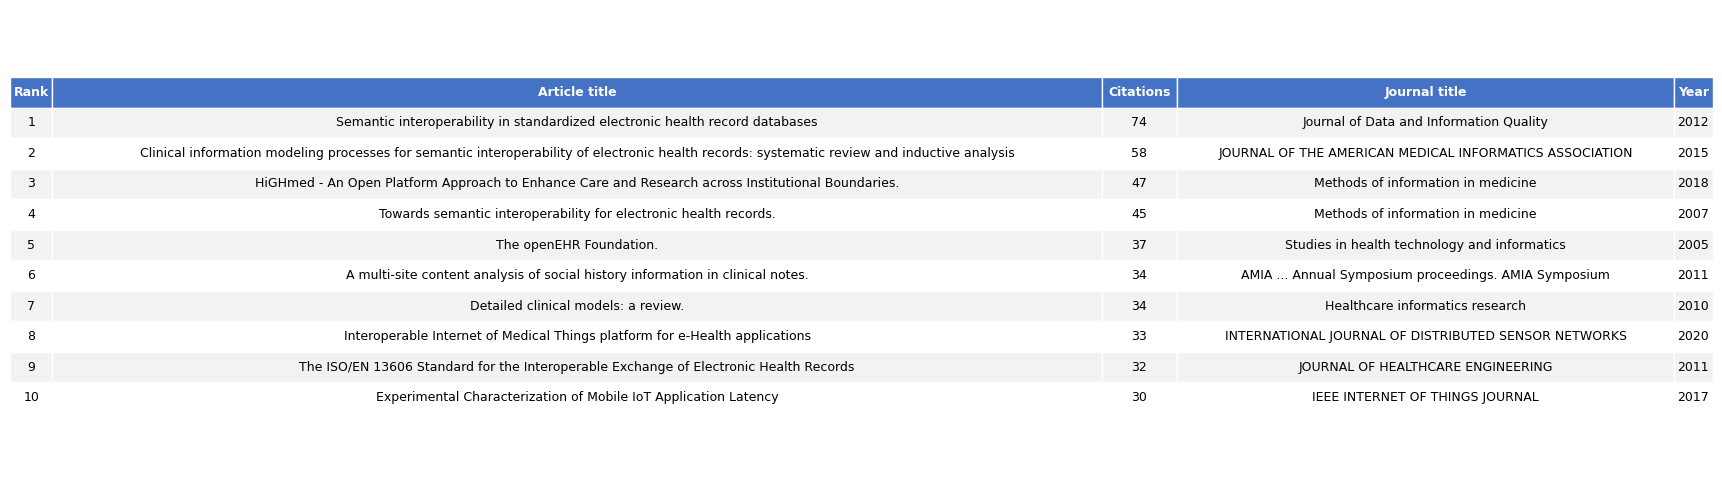

In [1]:
import matplotlib.pyplot as plt
import os
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

df = DATASET()

# Assuming df is your DataFrame
top_most_cited_df = df.sort_values('citation_count', ascending=False).reset_index(drop=True)
top_most_cited_df['Rank'] = top_most_cited_df.index + 1

if SAVE_MODE:
    of = OUTPUT_DIR / "top_most_cited_article.csv"
    top_most_cited_df.to_csv(of)
    print(f"`{os.path.basename(of)}` as complete list Saved.")

top_most_cited_df = top_most_cited_df.head(10)

data = top_most_cited_df[['Rank', 'title', 'citation_count', 'publisher', 'year']]
data.columns = ['Rank', 'Article title', 'Citations', 'Journal title', 'Year']

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

table = ax.table(cellText=data.values,
                 colLabels=data.columns,
                 cellLoc='center',
                 loc='center')

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

for k, cell in table._cells.items():
    cell.set_edgecolor('w')
    if k[0] == 0:
        cell.set_facecolor('#4472C4')
        cell.set_text_props(weight='bold', color='w')
    elif k[0] % 2 == 1:
        cell.set_facecolor('#F2F2F2')
    else:
        cell.set_facecolor('w')

table.auto_set_column_width(col=list(range(len(data.columns))))

plt.tight_layout()
if SAVE_MODE:
    of = OUTPUT_DIR  / "top_most_cited_article.png"
    plt.savefig(of)
    print(f"`{os.path.basename(of)}` as chart saved.")
dataframe_to_markdown(data, table_name="The top 10 most cited works of literature")
plt.show()


## Table 2 – Top 10 Contributing Countries

`countries_by_publication.csv` as csv file saved.
`top_10_countries_by_publication.png` as chart saved.


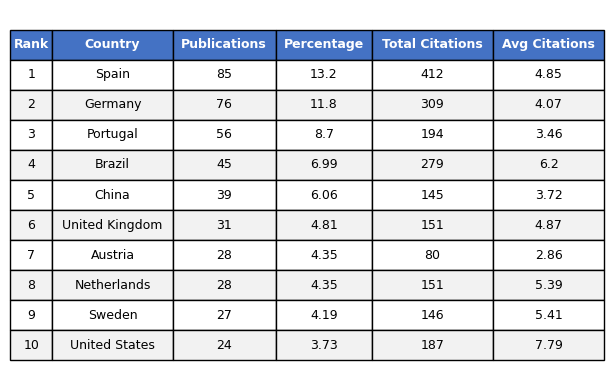


Top 10 Countries by Publication
| Rank | Country | Publications | Percentage | Total Citations | Avg Citations |
| --- | --- | --- | --- | --- | --- |
| 1 | Spain | 85 | 13.2 | 412 | 4.85 |
| 2 | Germany | 76 | 11.8 | 309 | 4.07 |
| 3 | Portugal | 56 | 8.7 | 194 | 3.46 |
| 4 | Brazil | 45 | 6.99 | 279 | 6.2 |
| 5 | China | 39 | 6.06 | 145 | 3.72 |
| 6 | United Kingdom | 31 | 4.81 | 151 | 4.87 |
| 7 | Austria | 28 | 4.35 | 80 | 2.86 |
| 8 | Netherlands | 28 | 4.35 | 151 | 5.39 |
| 9 | Sweden | 27 | 4.19 | 146 | 5.41 |
| 10 | United States | 24 | 3.73 | 187 | 7.79 |



In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

df = DATASET()


# Step 1: Explode the country list column
df_exploded = df.explode('affiliation_integration_country')

# Step 2: Calculate country-wise statistics
country_stats = df_exploded.groupby('affiliation_integration_country').agg({
    'title': 'count',
    'citation_count': 'sum'
}).reset_index()

country_stats = country_stats.rename(columns={
    'title': 'Publications',
    'citation_count': 'Total Citations'
})

# Step 3: Calculate percentages and average citations
total_publications = country_stats['Publications'].sum()
country_stats['Percentage'] = (country_stats['Publications'] / total_publications * 100)
country_stats['Avg Citations'] = country_stats['Total Citations'] / country_stats['Publications']

# Step 4: Select top 10 countries and add rank
# Before Save in csv
if SAVE_MODE:
    of = OUTPUT_DIR / "countries_by_publication.csv"
    country_stats.to_csv(of)
    print(f"`{os.path.basename(of)}` as csv file saved.")
    
country_stats = country_stats.sort_values('Publications', ascending=False).head(10).reset_index(drop=True)
country_stats['Rank'] = country_stats.index + 1

# Step 5: Reorder columns
country_stats = country_stats[['Rank', 'affiliation_integration_country', 'Publications', 'Percentage', 'Total Citations', 'Avg Citations']]
country_stats = country_stats.rename(columns={'affiliation_integration_country': 'Country'})

# Step 6: Ensure numeric columns are of the correct data type
numeric_columns = ['Publications', 'Percentage', 'Total Citations', 'Avg Citations']
for col in numeric_columns:
    country_stats[col] = pd.to_numeric(country_stats[col], errors='coerce')

# Step 7: Round numeric values
country_stats[numeric_columns] = country_stats[numeric_columns].round(2)

# Step 8: Create the plot
fig, ax = plt.subplots(figsize=(5, 4))
ax.axis('off')

# Step 9: Create the table
table = ax.table(cellText=country_stats.values,
                 colLabels=country_stats.columns,
                 loc='center',
                 cellLoc='center')

# Step 10: Format the table
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)


# Step 11: Add zebra striping

# Style the header
for j, cell in enumerate(table._cells[(0, j)] for j in range(len(country_stats.columns))):
    cell.set_facecolor('#4472C4')
    cell.set_text_props(color='white', weight='bold')

for i in range(1, len(country_stats) + 1):
    for j in range(len(country_stats.columns)):
        cell = table._cells[(i, j)]
        if i % 2 == 0:
            cell.set_facecolor('#F2F2F2')
        else:
            cell.set_facecolor('white')

# Step 12: Adjust column widths
table.auto_set_column_width(col=list(range(len(country_stats.columns))))

# Step 13: Display the plot
plt.tight_layout()
if SAVE_MODE:
    of = OUTPUT_DIR  / "top_10_countries_by_publication.png"
    plt.savefig(of)
    print(f"`{os.path.basename(of)}` as chart saved.")

plt.show()
t = dataframe_to_markdown(country_stats, table_name="Top 10 Countries by Publication")


## Figure 3 – Country co-occurrence network

## Table 3 - Top 10 Journals by publications

`journal_list.csv` as csv file saved.
`top_10_journal_by_publications.png` as chart picture saved.


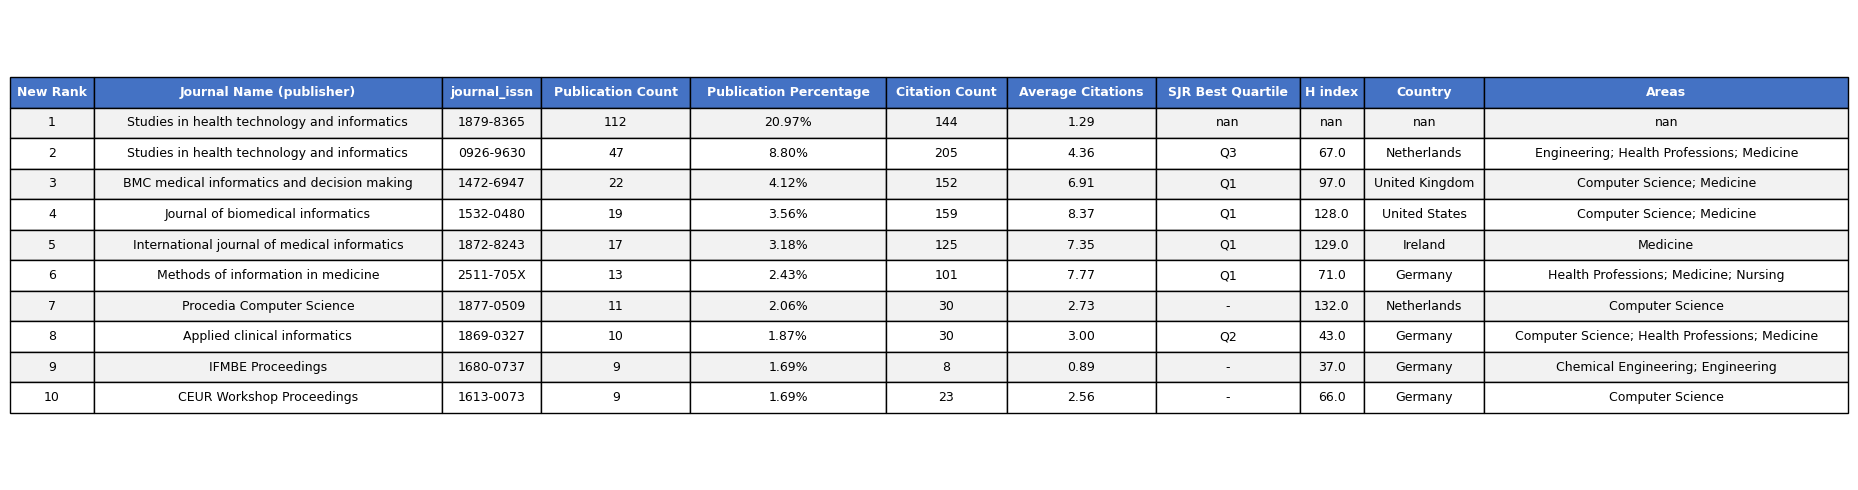


Top 10 Journal by publications
| Title | Journal Name (publisher) | journal_issn | Publication Count | Citation Count | Average Citations | SJR Best Quartile | H index | Country | Areas | New Rank | Publication Percentage |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| nan | Studies in health technology and informatics | 1879-8365 | 112 | 144 | 1.29 | nan | nan | nan | nan | 1 | 20.97 |
| Studies in Health Technology and Informatics | Studies in health technology and informatics | 0926-9630 | 47 | 205 | 4.36 | Q3 | 67.0 | Netherlands | Engineering; Health Professions; Medicine | 2 | 8.8 |
| BMC Medical Informatics and Decision Making | BMC medical informatics and decision making | 1472-6947 | 22 | 152 | 6.91 | Q1 | 97.0 | United Kingdom | Computer Science; Medicine | 3 | 4.12 |
| Journal of Biomedical Informatics | Journal of biomedical informatics | 1532-0480 | 19 | 159 | 8.37 | Q1 | 128.0 | United States | Computer Science; Medicine | 4 | 3.56 |
| Inter

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from src.config import OUTPUT_DIR, SAVE_MODE, DATA_DIR
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

df = DATASET()

# Create base DataFrame
new_df = pd.DataFrame({
    'Rank': range(1, len(df) + 1),
    'Journal Name (publisher)': df['publisher'],
    'journal_issn': df['journal_issn'],
    'Publication Count': 1,
    'Citation Count': df['citation_count']
})

# Group by journal and aggregate
result_df = new_df.groupby(['Journal Name (publisher)', 'journal_issn']).agg({
    'Publication Count': 'sum',
    'Citation Count': 'sum'
}).reset_index()

# Calculate Average Citations per Article (CPA)
result_df['Average Citations'] = result_df['Citation Count'] / result_df['Publication Count']
result_df['Average Citations'] = result_df['Average Citations'].round(2)

# Recompute rank based on Citation Count
result_df['Rank'] = result_df['Citation Count'].rank(method='dense', ascending=False).astype(int)

# Reorder columns
result_df = result_df[['Rank', 'Journal Name (publisher)', 'journal_issn',
                       'Publication Count', 'Citation Count', 'Average Citations']]

# Sort by Rank
result_df = result_df.sort_values('Rank').reset_index(drop=True)

# Read the scimagojr CSV file
scimagojr_df = pd.read_csv(DATA_DIR / 'scimagojr 2023_normal_issn.csv')

# Merge the dataframes
merged_df = pd.merge(result_df, scimagojr_df, left_on='journal_issn', right_on='normal_issn', how='left')

# Drop redundant 'normal_issn'
merged_df = merged_df.drop('normal_issn', axis=1)

# Reorder the columns
column_order = ['Title', 'Journal Name (publisher)', 'journal_issn',
                'Publication Count', 'Citation Count', 'Average Citations',
                'SJR Best Quartile', 'H index', 'Country', 'Areas']
merged_df = merged_df[column_order]

# Save merged data
if SAVE_MODE:
    of = OUTPUT_DIR / "journal_list.csv"
    merged_df.to_csv(of, index=False)
    print(f"`{os.path.basename(of)}` as csv file saved.")

# Check for empty dataframe
if merged_df.empty:
    print("The dataframe is empty. No table can be created.")

# Ensure required columns
required_columns = ['Publication Count', 'Journal Name (publisher)', 'journal_issn',
                    'Citation Count', 'Average Citations',
                    'SJR Best Quartile', 'H index', 'Country', 'Areas']
if not all(col in merged_df.columns for col in required_columns):
    print("Some required columns are missing from the dataframe.")

# Sort by Publication Count and get top 10
top_10 = merged_df.sort_values('Publication Count', ascending=False).head(10).reset_index(drop=True)

# Re-rank
top_10['New Rank'] = range(1, 11)

# Calculate percentage of total publications
total_publications = merged_df['Publication Count'].sum()
top_10['Publication Percentage'] = (top_10['Publication Count'] / total_publications * 100).round(2)

# Prepare data for the table
columns = ['New Rank', 'Journal Name (publisher)', 'journal_issn', 'Publication Count',
           'Publication Percentage', 'Citation Count', 'Average Citations',
           'SJR Best Quartile', 'H index', 'Country', 'Areas']

data = [top_10[col].tolist() for col in columns]

# Format percentage and large numbers
data[4] = [f"{x:.2f}%" for x in data[4]]  # Publication Percentage
data[3] = [f"{x:,}" for x in data[3]]    # Publication Count
data[5] = [f"{x:,}" for x in data[5]]    # Citation Count
data[6] = [f"{x:.2f}" for x in data[6]]  # Average Citations

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 5))

# Hide axes
ax.axis('off')

# Create table
table = ax.table(cellText=list(zip(*data)),
                 colLabels=columns,
                 loc='center',
                 cellLoc='center')

# Set font size
table.auto_set_font_size(False)
table.set_fontsize(9)

# Style the table
table.auto_set_column_width(col=list(range(len(columns))))
table.scale(1, 1.5)

# Color header
for j, cell in enumerate(table._cells[(0, j)] for j in range(len(columns))):
    cell.set_facecolor('#4472C4')
    cell.set_text_props(color='white', weight='bold')

# Zebra stripes
for i in range(1, len(top_10) + 1):
    for j in range(len(columns)):
        cell = table._cells[(i, j)]
        cell.set_facecolor('#F2F2F2' if i % 2 else 'white')

plt.tight_layout()
if SAVE_MODE:
    of = OUTPUT_DIR / "top_10_journal_by_publications.png"
    plt.savefig(of)
    print(f"`{os.path.basename(of)}` as chart picture saved.")

plt.show()
t = dataframe_to_markdown(top_10, table_name="Top 10 Journal by publications")

## Figure 4 – Journal Productivity vs. Citation Impact (Bubble size is proportional to total citations per journal)

`journal_productivity_vs_citation_impact.png` saved.


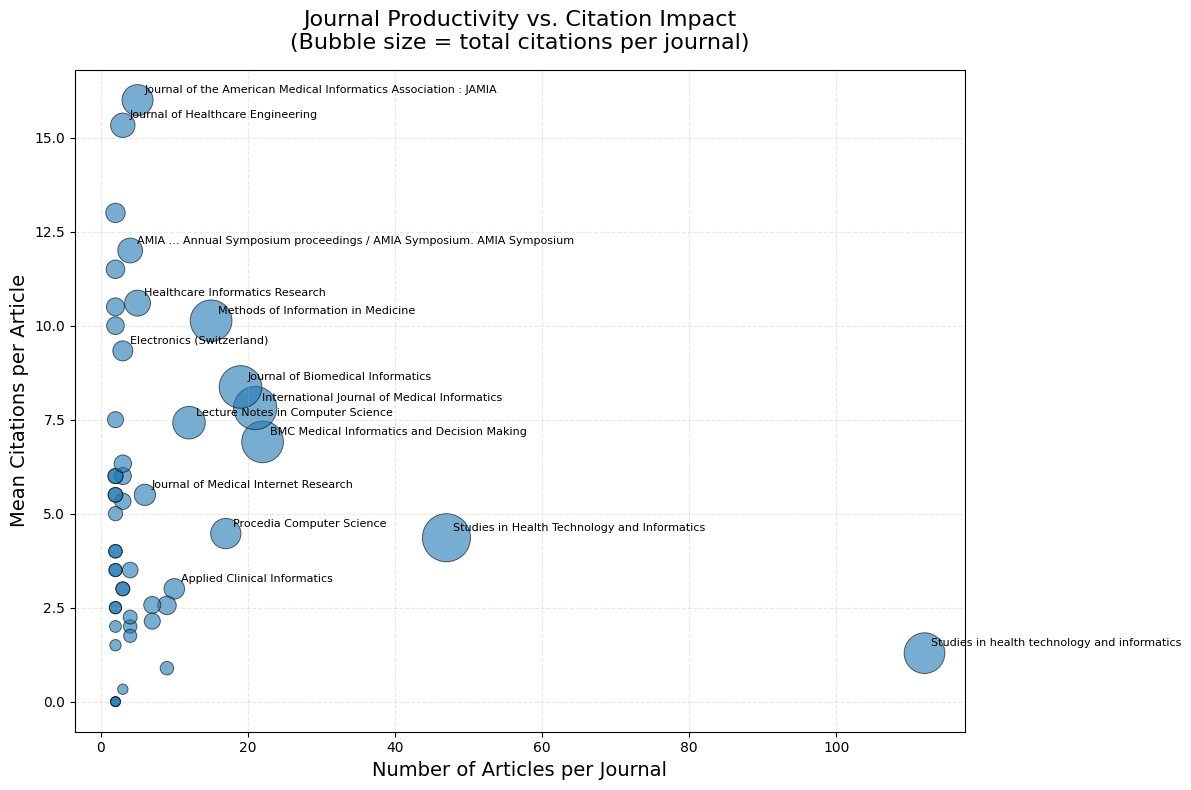


Journal Productivity vs. Citation Impact
| Journal | Num_Articles | Total_Citations | Mean_Citations |
| --- | --- | --- | --- |
| Studies in Health Technology and Informatics | 47 | 205 | 4.36 |
| International Journal of Medical Informatics | 21 | 164 | 7.81 |
| Journal of Biomedical Informatics | 19 | 159 | 8.37 |
| BMC Medical Informatics and Decision Making | 22 | 152 | 6.91 |
| Methods of Information in Medicine | 15 | 152 | 10.13 |
| Studies in health technology and informatics | 112 | 144 | 1.29 |
| Lecture Notes in Computer Science | 12 | 89 | 7.42 |
| Journal of the American Medical Informatics Association : JAMIA | 5 | 80 | 16.0 |
| Procedia Computer Science | 17 | 76 | 4.47 |
| Healthcare Informatics Research | 5 | 53 | 10.6 |
| AMIA ... Annual Symposium proceedings / AMIA Symposium. AMIA Symposium | 4 | 48 | 12.0 |
| Journal of Healthcare Engineering | 3 | 46 | 15.33 |
| Journal of Medical Internet Research | 6 | 33 | 5.5 |
| Applied Clinical Informatics | 10 | 30 | 3.0 |

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ======================================================
# TITLE: Journal Productivity vs. Citation Impact
#        (x = #articles, y = citations/article, bubble size = total citations)
# ======================================================

# -----------------------------
# Parameters (easily adjustable)
# -----------------------------
JOURNAL_KEY = "journal_title"   # or "journal_issn" if you prefer
MIN_ARTICLES = 2                # minimum number of articles per journal to include
TOP_LABELS = 15                 # label top N journals by total citations
BASE_MARKER_SIZE = 50           # minimum bubble size
MAX_MARKER_SIZE = 1200          # maximum bubble size

# --- Load dataset
df = DATASET()

# --- Ensure citation_count is numeric
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

# --- Drop rows with missing journal identifier
df_journal = df.dropna(subset=[JOURNAL_KEY]).copy()

# --- Aggregate statistics per journal
journal_stats_df = (
    df_journal.groupby(JOURNAL_KEY, as_index=False)
    .agg(
        Num_Articles=("DBUID", "nunique"),
        Total_Citations=("citation_count", "sum"),
        Mean_Citations=("citation_count", "mean"),
    )
    .rename(columns={JOURNAL_KEY: "Journal"})
)

# --- Filter journals by minimum article count
journal_stats_df = journal_stats_df[journal_stats_df["Num_Articles"] >= MIN_ARTICLES].copy()

# --- Ensure numeric types and rounding
journal_stats_df["Num_Articles"] = pd.to_numeric(
    journal_stats_df["Num_Articles"], errors="coerce"
).fillna(0).astype(int)

journal_stats_df["Total_Citations"] = pd.to_numeric(
    journal_stats_df["Total_Citations"], errors="coerce"
).fillna(0)

journal_stats_df["Mean_Citations"] = pd.to_numeric(
    journal_stats_df["Mean_Citations"], errors="coerce"
).fillna(0).round(2)

# --- Handle case of no journals passing the filter
if journal_stats_df.empty:
    print(
        f"No journals found with at least {MIN_ARTICLES} articles. "
        "Try lowering MIN_ARTICLES."
    )
else:
    # --- Bubble size scaling based on total citations
    max_total_cites = journal_stats_df["Total_Citations"].max()
    if max_total_cites <= 0:
        size_scaled = [BASE_MARKER_SIZE] * len(journal_stats_df)
    else:
        size_scaled = (
            BASE_MARKER_SIZE
            + (journal_stats_df["Total_Citations"] / max_total_cites)
            * (MAX_MARKER_SIZE - BASE_MARKER_SIZE)
        )

    # --- Prepare figure
    plt.figure(figsize=(12, 8))

    x = journal_stats_df["Num_Articles"]
    y = journal_stats_df["Mean_Citations"]

    scatter = plt.scatter(
        x,
        y,
        s=size_scaled,
        alpha=0.6,
        edgecolor="black",
        linewidth=0.7,
    )

    # --- Title and axes
    plt.title(
        "Journal Productivity vs. Citation Impact\n"
        "(Bubble size = total citations per journal)",
        fontsize=16,
        pad=15,
    )
    plt.xlabel("Number of Articles per Journal", fontsize=14)
    plt.ylabel("Mean Citations per Article", fontsize=14)

    plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8, prune=None))
    plt.grid(True, linestyle="--", alpha=0.3)

    # --- Label top N journals by total citations
    top_journals = (
        journal_stats_df.sort_values("Total_Citations", ascending=False)
        .head(TOP_LABELS)
    )
    for _, row in top_journals.iterrows():
        plt.annotate(
            row["Journal"],
            xy=(row["Num_Articles"], row["Mean_Citations"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
        )

    plt.tight_layout()

    # --- Save figure
    if SAVE_MODE:
        png_file = OUTPUT_DIR / "journal_productivity_vs_citation_impact.png"
        plt.savefig(png_file, dpi=300, bbox_inches="tight")
        print(f"`{os.path.basename(png_file)}` saved.")

    plt.show()
    plt.close()

# --- Sort and export table for markdown
journal_stats_sorted = journal_stats_df.sort_values(
    "Total_Citations", ascending=False
).reset_index(drop=True)

table_markdown = dataframe_to_markdown(
    journal_stats_sorted,
    table_name="Journal Productivity vs. Citation Impact",
)


## Table 4 – Distribution of Thematic Categories

`distribution_of_assigned_categories.png` saved.


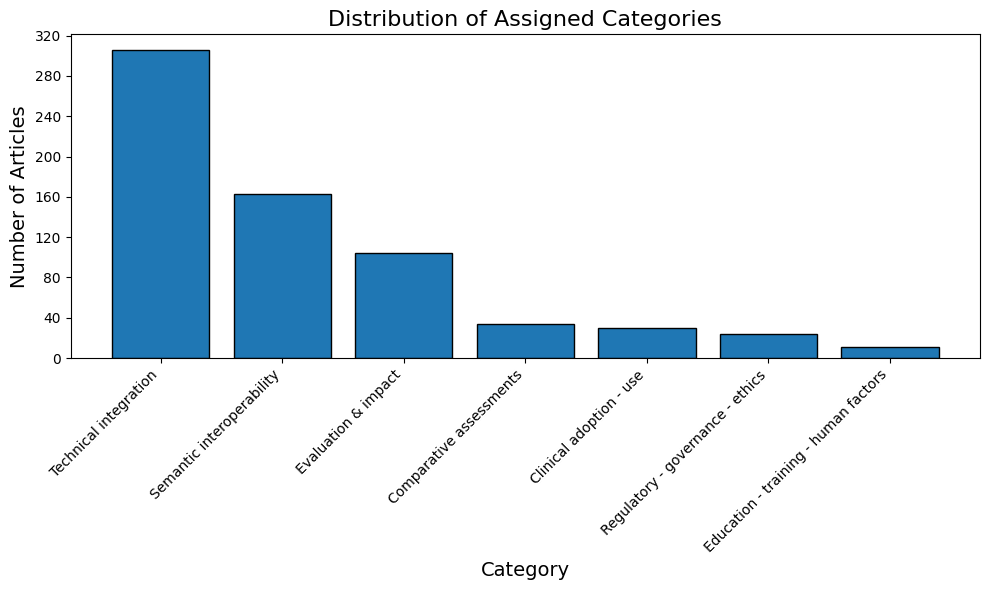


Distribution of Assigned Categories
| Category | Count | Percent |
| --- | --- | --- |
| Technical integration | 306 | 45.54 |
| Semantic interoperability | 163 | 24.26 |
| Evaluation & impact | 104 | 15.48 |
| Comparative assessments | 34 | 5.06 |
| Clinical adoption - use | 30 | 4.46 |
| Regulatory - governance - ethics | 24 | 3.57 |
| Education - training - human factors | 11 | 1.64 |



In [12]:
import pandas as pd
import os
import ast
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# --- Load dataset
df = DATASET()

# --- Convert stringified lists to actual Python lists
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except (ValueError, SyntaxError):
        return [val] if not pd.isna(val) else []

df["DEFA_assigned_category_v3"] = df["DEFA_assigned_category_v3"].apply(safe_eval)

# --- Explode list values and drop NaNs
df_exploded = df.explode("DEFA_assigned_category_v3").dropna(subset=["DEFA_assigned_category_v3"])

# --- Count categories (robust naming) -> always get 'Category' and 'Count'
category_counts_df = (
    df_exploded["DEFA_assigned_category_v3"]
    .value_counts()                         # Series: index = category, values = counts
    .rename_axis("Category")                # name the index
    .reset_index(name="Count")              # turn into DF with proper column names
)

# --- Ensure numeric dtype for Count
category_counts_df["Count"] = pd.to_numeric(category_counts_df["Count"], errors="coerce").fillna(0).astype(int)

# --- Add percent column
total = int(category_counts_df["Count"].sum())
category_counts_df["Percent"] = (100 * category_counts_df["Count"] / total).round(2)

# --- Plot bar chart
plt.figure(figsize=(10, 6))
ax = plt.bar(category_counts_df["Category"], category_counts_df["Count"], edgecolor="black")
plt.title("Distribution of Assigned Categories", fontsize=16)
plt.xlabel("Category", fontsize=14)
plt.ylabel("Number of Articles", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()

if SAVE_MODE:
    of = OUTPUT_DIR / "distribution_of_assigned_categories.png"
    plt.savefig(of, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(of)}` saved.")

plt.show()
plt.close()

# --- Send DataFrame to your markdown helper
t = dataframe_to_markdown(category_counts_df, table_name="Distribution of Assigned Categories")
category_counts_df.to_excel("Distribution of Thematic Categories.xlsx")


## Figure 5 – Keyword Co-occurrence Network (VOSviewer Visualization)

## Figure 6 – Thematic Co-occurrence Heatmap

`thematic_cooccurrence_heatmap_top7.png` saved.


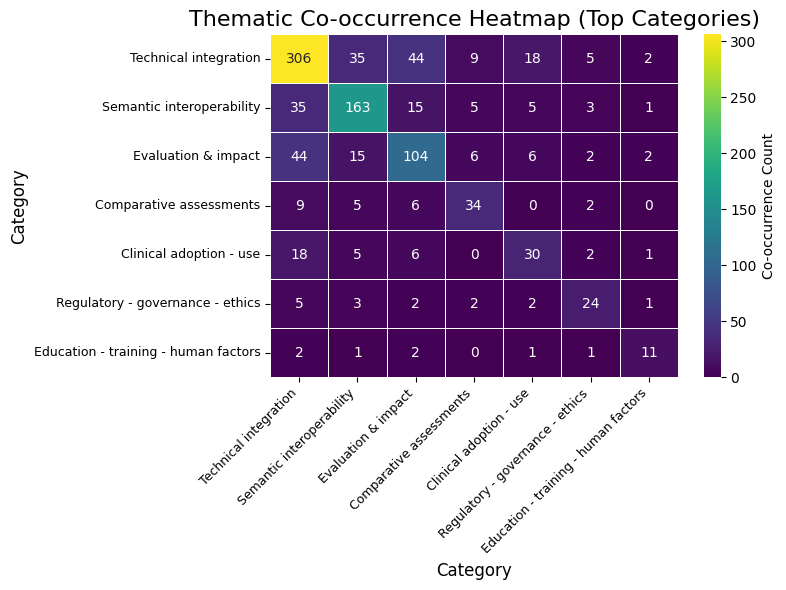


Thematic Co-occurrence Matrix (Top Categories)
| Category | Technical integration | Semantic interoperability | Evaluation & impact | Comparative assessments | Clinical adoption - use | Regulatory - governance - ethics | Education - training - human factors |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Technical integration | 306 | 35 | 44 | 9 | 18 | 5 | 2 |
| Semantic interoperability | 35 | 163 | 15 | 5 | 5 | 3 | 1 |
| Evaluation & impact | 44 | 15 | 104 | 6 | 6 | 2 | 2 |
| Comparative assessments | 9 | 5 | 6 | 34 | 0 | 2 | 0 |
| Clinical adoption - use | 18 | 5 | 6 | 0 | 30 | 2 | 1 |
| Regulatory - governance - ethics | 5 | 3 | 2 | 2 | 2 | 24 | 1 |
| Education - training - human factors | 2 | 1 | 2 | 0 | 1 | 1 | 11 |



In [5]:
import pandas as pd
import os
import ast
import itertools
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ============================================================
# Load dataset
# ============================================================
df = DATASET()

# ------------------------------------------------------------
# Helper to convert string → Python list safely
# ------------------------------------------------------------
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except (ValueError, SyntaxError):
        return [val] if not pd.isna(val) else []

# Convert thematic category field
df["DEFA_assigned_category_v3"] = df["DEFA_assigned_category_v3"].apply(safe_eval)

# ------------------------------------------------------------
# Determine top thematic categories (for 7×7 matrix)
# ------------------------------------------------------------
# Explode to count individual category frequencies
df_exploded = df.explode("DEFA_assigned_category_v3").dropna(subset=["DEFA_assigned_category_v3"])

category_counts = (
    df_exploded["DEFA_assigned_category_v3"]
    .value_counts()
)

# Select top 7 categories (or fewer if less exist)
TOP_N = 7
top_categories = category_counts.head(TOP_N).index.tolist()
if len(top_categories) == 0:
    raise ValueError("No thematic categories found to build a co-occurrence matrix.")

# ------------------------------------------------------------
# Build co-occurrence matrix for top categories
# ------------------------------------------------------------
# Initialize square DataFrame (co-occurrence counts)
coocc_df = pd.DataFrame(
    0,
    index=top_categories,
    columns=top_categories,
    dtype=int
)

# Iterate over articles and accumulate co-occurrences
for cats in df["DEFA_assigned_category_v3"]:
    if not isinstance(cats, (list, tuple, set)):
        continue

    # Keep only top categories and make unique
    cats_filtered = sorted(set(c for c in cats if c in top_categories))
    if not cats_filtered:
        continue

    # Diagonal: each category co-occurs with itself in this article
    for c in cats_filtered:
        coocc_df.loc[c, c] += 1

    # Off-diagonal: unordered pairs (a, b)
    for a, b in itertools.combinations(cats_filtered, 2):
        coocc_df.loc[a, b] += 1
        coocc_df.loc[b, a] += 1  # make symmetric

# ------------------------------------------------------------
# Plot 7×7 heatmap of co-occurrence intensity
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

sns.heatmap(
    coocc_df,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Co-occurrence Count"}
)

plt.title("Thematic Co-occurrence Heatmap (Top Categories)", fontsize=16)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

# Save figure
if SAVE_MODE:
    png_file = OUTPUT_DIR / "thematic_cooccurrence_heatmap_top7.png"
    plt.savefig(png_file, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file)}` saved.")

plt.show()
plt.close()

# ------------------------------------------------------------
# Export co-occurrence matrix as markdown (wide but simple)
# ------------------------------------------------------------
coocc_df_reset = coocc_df.reset_index().rename(columns={"index": "Category"})
t = dataframe_to_markdown(
    coocc_df_reset,
    table_name="Thematic Co-occurrence Matrix (Top Categories)"
)


## Supplementary Figure S1
Rolling compound annual growth rate (CAGR) of annual publications (2002–2025). Rolling CAGR was calculated over a moving time window to illustrate temporal variation in relative growth rates; overall CAGR for the study period was 8.83%.

Compound Annual Growth Rate (CAGR) of Annual Publications Over Time

**CAGR (Compound Annual Growth Rate)** is a metric used in bibliometrics to measure the average annual growth of a variable (such as publications or citations) over a multi-year period, assuming a constant compounded growth rate.

**Formula:**

$$
CAGR = \left( \frac{V_{final}}{V_{initial}} \right)^{\frac{1}{n-1}} - 1
$$

Where:

* $ V_{initial} $ = value in the first year
* $ V_{final} $ = value in the last year
* $ n $ = number of years in the period


,year,annual_count
0,2002,2
1,2003,1
2,2004,3
3,2005,8
4,2006,8


Overall CAGR (decimal): 0.0883
Overall CAGR (percent): 8.83%


,year,annual_count,cagr_from_start
0,2002,2,NaN
1,2003,1,-0.500000
2,2004,3,0.224745
3,2005,8,0.587401
4,2006,8,0.414214
5,2007,11,0.406282
6,2008,14,0.383088
7,2009,20,0.389495
8,2010,27,0.384496
9,2011,30,0.351067



Annual Publications and CAGR from Start
| year | annual_count | cagr_from_start |
| --- | --- | --- |
| 2002 | 2 | nan |
| 2003 | 1 | -0.5 |
| 2004 | 3 | 0.22474487139158894 |
| 2005 | 8 | 0.5874010519681994 |
| 2006 | 8 | 0.41421356237309515 |
| 2007 | 11 | 0.4062823883876352 |
| 2008 | 14 | 0.3830875542684884 |
| 2009 | 20 | 0.3894954943731377 |
| 2010 | 27 | 0.3844960500986694 |
| 2011 | 30 | 0.3510667516017707 |
| 2012 | 32 | 0.3195079107728942 |
| 2013 | 40 | 0.31303243448788387 |
| 2014 | 33 | 0.26315601755176043 |
| 2015 | 43 | 0.2661794659547838 |
| 2016 | 24 | 0.1942200949688373 |
| 2017 | 44 | 0.2288386014896442 |
| 2018 | 22 | 0.16168141877174813 |
| 2019 | 35 | 0.1833681745905582 |
| 2020 | 29 | 0.160166830132485 |
| 2021 | 23 | 0.13717211621400227 |
| 2022 | 26 | 0.13683429785559853 |
| 2023 | 19 | 0.11316172961287796 |
| 2024 | 26 | 0.12365707011510096 |
| 2025 | 14 | 0.08828687884810638 |

| year | annual_count | cagr_from_start |
| --- | --- | --- |
| 2002 | 2 | nan |


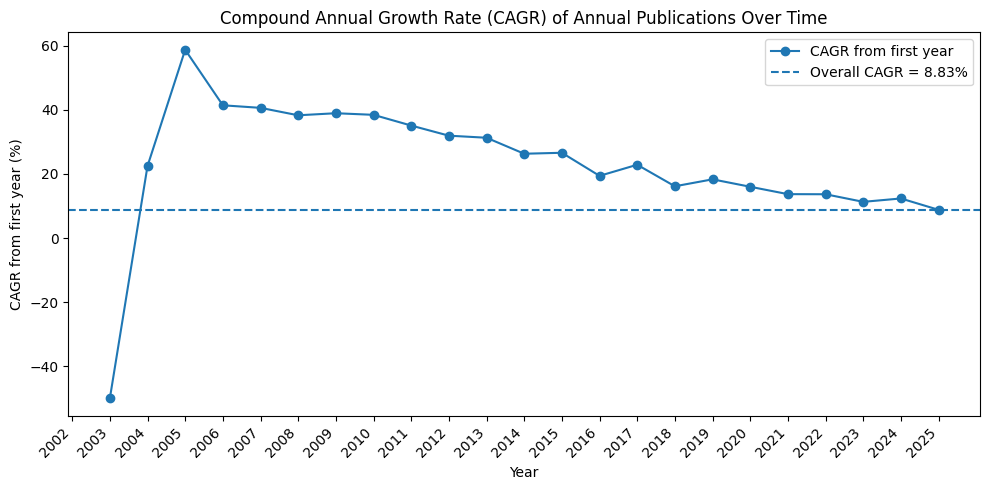

The compound annual growth rate (CAGR) of annual publications over the study period was 8.83%.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from src.lib_dataset import DATASET
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown

# -------------------------------------------------------
# Load and clean dataset
# -------------------------------------------------------
df = DATASET()

# Clean year column
df = df[df["year"].notna()]
df["year"] = df["year"].astype(str).str.strip()
df = df[df["year"] != ""]
df["year"] = df["year"].astype(int)

# -------------------------------------------------------
# Compute annual publication counts
# -------------------------------------------------------
annual_counts = (
    df.groupby("year")
      .size()
      .reset_index(name="annual_count")
      .sort_values("year")
      .reset_index(drop=True)
)

display(annual_counts.head())

# -------------------------------------------------------
# Compute overall CAGR (from first year to last year)
# -------------------------------------------------------
first_value = annual_counts["annual_count"].iloc[0]
last_value = annual_counts["annual_count"].iloc[-1]
n_years = len(annual_counts) - 1  # number of intervals

if first_value > 0 and n_years > 0:
    overall_cagr = (last_value / first_value) ** (1 / n_years) - 1
else:
    overall_cagr = np.nan

print(f"Overall CAGR (decimal): {overall_cagr:.4f}")
print(f"Overall CAGR (percent): {overall_cagr * 100:.2f}%")

# -------------------------------------------------------
# Compute CAGR over time (from first year to each year)
# -------------------------------------------------------
# For year i, CAGR_from_start = (value_i / value_0)^(1 / i) - 1
cagr_series = [np.nan]  # first year has no CAGR (no interval)

for i in range(1, len(annual_counts)):
    v_t = annual_counts["annual_count"].iloc[i]
    v_0 = first_value
    n = i  # number of intervals from first year
    if v_0 > 0:
        cagr_t = (v_t / v_0) ** (1 / n) - 1
    else:
        cagr_t = np.nan
    cagr_series.append(cagr_t)

annual_counts["cagr_from_start"] = cagr_series

display(annual_counts)

# Optional: markdown table for reporting
t_cagr = dataframe_to_markdown(
    annual_counts,
    table_name="Annual Publications and CAGR from Start"
)
print(t_cagr)

# -------------------------------------------------------
# Plot CAGR over time
# -------------------------------------------------------
plt.figure(figsize=(10, 5))

# Plot CAGR from start (in percent)
plt.plot(
    annual_counts["year"],
    annual_counts["cagr_from_start"] * 100,
    marker="o",
    linestyle="-",
    label="CAGR from first year"
)

# Optional: horizontal line for overall CAGR (same as last point, but explicit)
if not np.isnan(overall_cagr):
    plt.axhline(
        y=overall_cagr * 100,
        linestyle="--",
        label=f"Overall CAGR = {overall_cagr * 100:.2f}%"
    )

plt.xlabel("Year")
plt.ylabel("CAGR from first year (%)")
plt.title("Compound Annual Growth Rate (CAGR) of Annual Publications Over Time")
plt.xticks(annual_counts["year"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()

# Save figure if SAVE_MODE is enabled
if SAVE_MODE:
    of = OUTPUT_DIR / "cagr_over_time.png"
    plt.savefig(of)
    print(f"`{os.path.basename(of)}` chart saved.")

plt.show()

# -------------------------------------------------------
# Optional: ready-to-use sentence for the manuscript
# -------------------------------------------------------
if not np.isnan(overall_cagr):
    print(
        f"The compound annual growth rate (CAGR) of annual publications over the study period "
        f"was {overall_cagr * 100:.2f}%."
    )


## Supplementary Figure S2 
Annual publication and citation trends (2002–2025). Citation counts are shown by publication year to illustrate temporal alignment between output and citation accumulation.

`annual_publications_vs_citations_dual_axis.png` saved.


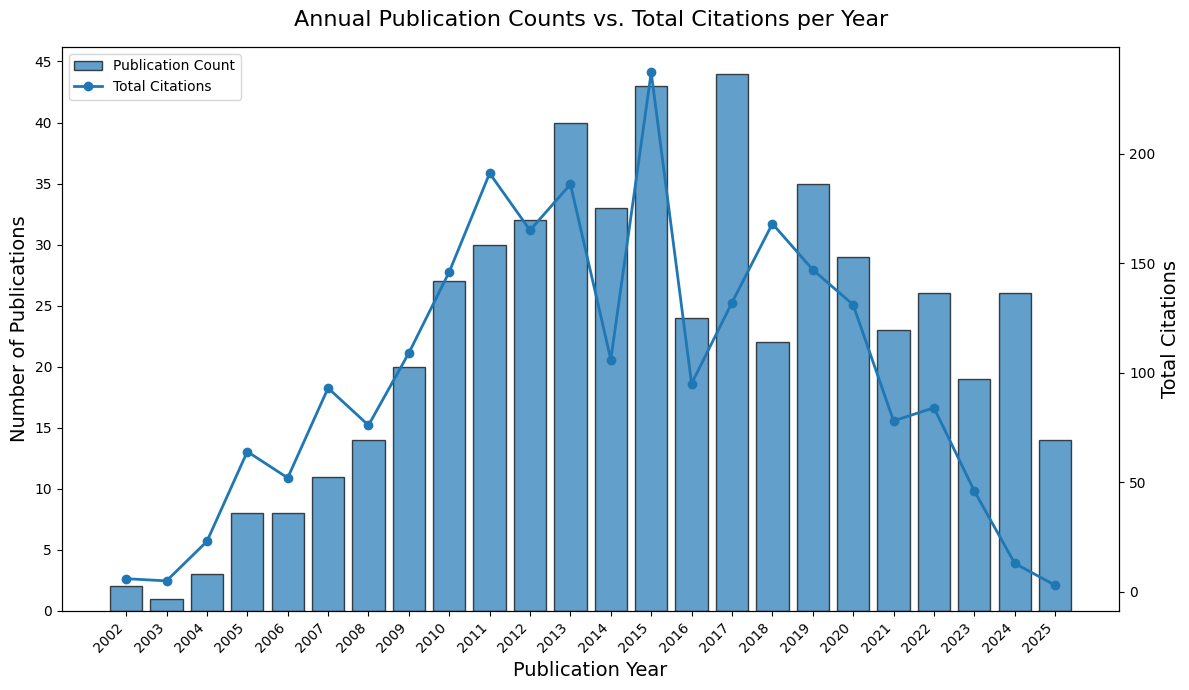


Annual Publications and Total Citations per Year
| year | Publication_Count | Total_Citations |
| --- | --- | --- |
| 2002 | 2 | 6 |
| 2003 | 1 | 5 |
| 2004 | 3 | 23 |
| 2005 | 8 | 64 |
| 2006 | 8 | 52 |
| 2007 | 11 | 93 |
| 2008 | 14 | 76 |
| 2009 | 20 | 109 |
| 2010 | 27 | 146 |
| 2011 | 30 | 191 |
| 2012 | 32 | 165 |
| 2013 | 40 | 186 |
| 2014 | 33 | 106 |
| 2015 | 43 | 237 |
| 2016 | 24 | 95 |
| 2017 | 44 | 132 |
| 2018 | 22 | 168 |
| 2019 | 35 | 147 |
| 2020 | 29 | 131 |
| 2021 | 23 | 78 |
| 2022 | 26 | 84 |
| 2023 | 19 | 46 |
| 2024 | 26 | 13 |
| 2025 | 14 | 3 |



In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ======================================================
# TITLE: Annual Publications vs. Total Citations (Dual-Axis Chart)
# ======================================================

# --- Load dataset
df = DATASET()

# --- Ensure correct dtypes for year and citation_count
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0).astype(int)

# --- Drop rows with missing or invalid year
df_clean = df.dropna(subset=["year"]).copy()
df_clean["year"] = df_clean["year"].astype(int)

# --- Aggregate annual metrics:
#     - Publication_Count: number of articles per year
#     - Total_Citations: total citations accumulated per year
annual_metrics_df = (
    df_clean.groupby("year", as_index=False)
    .agg(
        Publication_Count=("DBUID", "count"),
        Total_Citations=("citation_count", "sum"),
    )
    .sort_values("year")
)

# --- Ensure numeric types are clean
annual_metrics_df["Publication_Count"] = pd.to_numeric(
    annual_metrics_df["Publication_Count"], errors="coerce"
).fillna(0).astype(int)

annual_metrics_df["Total_Citations"] = pd.to_numeric(
    annual_metrics_df["Total_Citations"], errors="coerce"
).fillna(0).astype(int)

# --- Plot dual-axis chart
fig, ax1 = plt.subplots(figsize=(12, 7))

years = annual_metrics_df["year"]
pub_counts = annual_metrics_df["Publication_Count"]
total_cites = annual_metrics_df["Total_Citations"]

# Bars: Publication count (left y-axis)
bars = ax1.bar(years, pub_counts, alpha=0.7, edgecolor="black", label="Publication Count")
ax1.set_xlabel("Publication Year", fontsize=14)
ax1.set_ylabel("Number of Publications", fontsize=14)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))

# Line: Total citations (right y-axis)
ax2 = ax1.twinx()
line = ax2.plot(years, total_cites, marker="o", linewidth=2, label="Total Citations")
ax2.set_ylabel("Total Citations", fontsize=14)

# --- Title and layout
plt.title("Annual Publication Counts vs. Total Citations per Year", fontsize=16, pad=15)
ax1.set_xticks(years)
ax1.set_xticklabels(years, rotation=45, ha="right")

# --- Combine legends from both axes
lines_labels = [(bars, "Publication Count"), (line[0], "Total Citations")]
labels = [l[1] for l in lines_labels]
handles = [l[0] for l in lines_labels]
ax1.legend(handles, labels, loc="upper left")

plt.tight_layout()

# --- Save figure
if SAVE_MODE:
    png_file = OUTPUT_DIR / "annual_publications_vs_citations_dual_axis.png"
    plt.savefig(png_file, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file)}` saved.")

plt.show()
plt.close()

# --- Send aggregated DataFrame to your markdown helper
table_markdown = dataframe_to_markdown(
    annual_metrics_df,
    table_name="Annual Publications and Total Citations per Year"
)


## Supplementary Figure S3
Annual International Collaboration Rate (ICR) for ISO 13606/openEHR publications (2002–2025). ICR represents the proportion of publications with at least one international co-author.


To quantify the degree of cross-national research cooperation, we computed the **International Collaboration Rate (ICR)**, which measures the share of publications co-authored by researchers affiliated with **two or more distinct countries**. An article is classified as internationally collaborative if its affiliation list includes contributors from at least two different national origins. The ICR is formally defined as:

$$
ICR = \frac{N_{\text{international}}}{N_{\text{total}}}
$$

where $ N_{\text{international}} $ denotes the number of internationally co-authored articles, and $ N_{\text{total}} $ represents the total number of articles in the dataset. Higher ICR values indicate stronger global interconnectedness and a greater reliance on cross-border scholarly collaboration.

Overall International Collaboration Rate (ICR): 0.157
`international_collaboration_rate_over_time.png` saved.


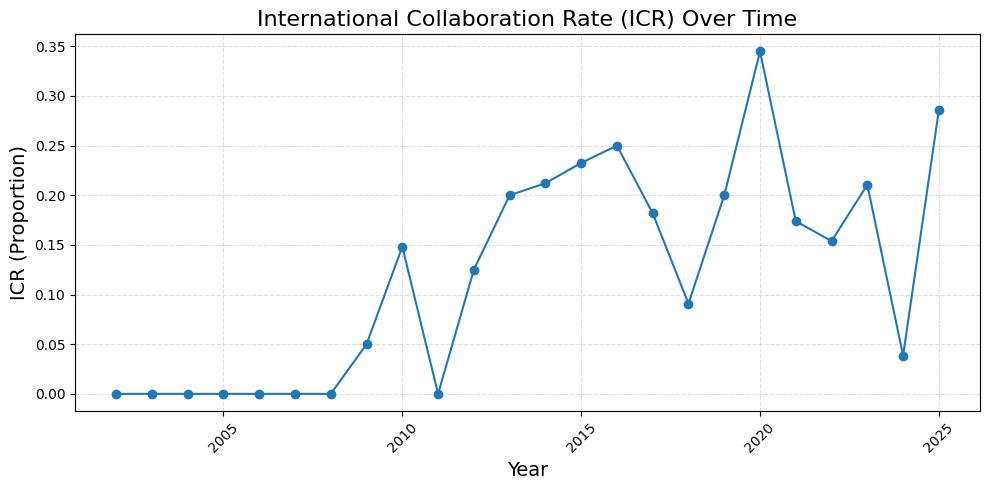


International Collaboration Rate (ICR) by Year
| Year | ICR |
| --- | --- |
| 2002 | 0.0 |
| 2003 | 0.0 |
| 2004 | 0.0 |
| 2005 | 0.0 |
| 2006 | 0.0 |
| 2007 | 0.0 |
| 2008 | 0.0 |
| 2009 | 0.05 |
| 2010 | 0.14814814814814814 |
| 2011 | 0.0 |
| 2012 | 0.125 |
| 2013 | 0.2 |
| 2014 | 0.21212121212121213 |
| 2015 | 0.23255813953488372 |
| 2016 | 0.25 |
| 2017 | 0.18181818181818182 |
| 2018 | 0.09090909090909091 |
| 2019 | 0.2 |
| 2020 | 0.3448275862068966 |
| 2021 | 0.17391304347826086 |
| 2022 | 0.15384615384615385 |
| 2023 | 0.21052631578947367 |
| 2024 | 0.038461538461538464 |
| 2025 | 0.2857142857142857 |



In [8]:
import pandas as pd
import os
import ast
import numpy as np
import matplotlib.pyplot as plt

from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ============================================================
# Load dataset
# ============================================================
df = DATASET()

# ------------------------------------------------------------
# Helper: convert string → Python list safely
# ------------------------------------------------------------
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except Exception:
        return [val] if not pd.isna(val) else []

# Convert country list field
df["affiliation_integration_country"] = df["affiliation_integration_country"].apply(safe_eval)

# Ensure year is numeric
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"])
df["year"] = df["year"].astype(int)

# ============================================================
# Function to compute ICR from a dataframe
# ============================================================
def compute_icr(df_sub):
    """
    Computes International Collaboration Rate:
    ICR = % of articles that involve authors from >= 2 countries.
    """
    if df_sub.empty:
        return 0.0
    
    def is_international(country_list):
        unique_countries = {c for c in country_list if isinstance(c, str)}
        return len(unique_countries) >= 2
    
    international_mask = df_sub["affiliation_integration_country"].apply(is_international)
    
    return international_mask.mean()  # proportion (0–1)

# ============================================================
# 1) Overall ICR
# ============================================================
overall_icr = compute_icr(df)
print(f"Overall International Collaboration Rate (ICR): {overall_icr:.3f}")

# ============================================================
# 2) Yearly ICR (temporal collaboration trend)
# ============================================================
yearly_icr = []

for year, group in df.groupby("year"):
    icr_value = compute_icr(group)
    yearly_icr.append({"Year": year, "ICR": icr_value})

icr_df = pd.DataFrame(yearly_icr).sort_values("Year")

# ============================================================
# Plot: ICR over time
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(icr_df["Year"], icr_df["ICR"], marker="o")

plt.title("International Collaboration Rate (ICR) Over Time", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("ICR (Proportion)", fontsize=14)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

if SAVE_MODE:
    png_file = OUTPUT_DIR / "international_collaboration_rate_over_time.png"
    plt.savefig(png_file, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file)}` saved.")

plt.show()
plt.close()

# ------------------------------------------------------------
# Export table as markdown
# ------------------------------------------------------------
t = dataframe_to_markdown(
    icr_df,
    table_name="International Collaboration Rate (ICR) by Year"
)


## Supplementary Figure S4
Log–log distribution of author productivity consistent with Lotka’s Law.

Total unique authors: 1610
   n_papers  n_authors  Author_Share_%  Cumulative_Authors  Cumulative_Share_%
0         1       1180           73.29                1180               73.29
1         2        214           13.29                1394               86.58
2         3         93            5.78                1487               92.36
3         4         39            2.42                1526               94.78
4         5         23            1.43                1549               96.21
Estimated Lotka parameters:
  A_1 ≈ 1052.323
  alpha ≈ 2.350
`lotkas_law_loglog_plot.png` saved.


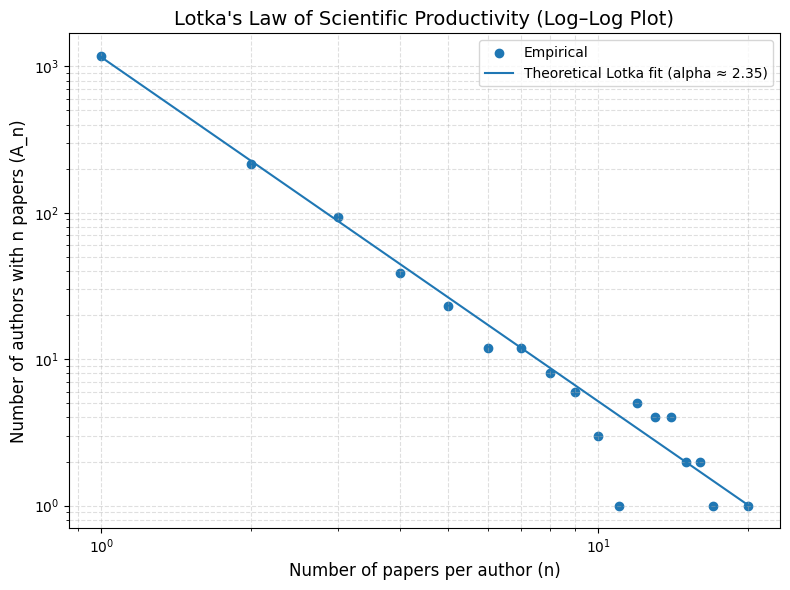

`lotkas_law_productivity_distribution.png` saved.


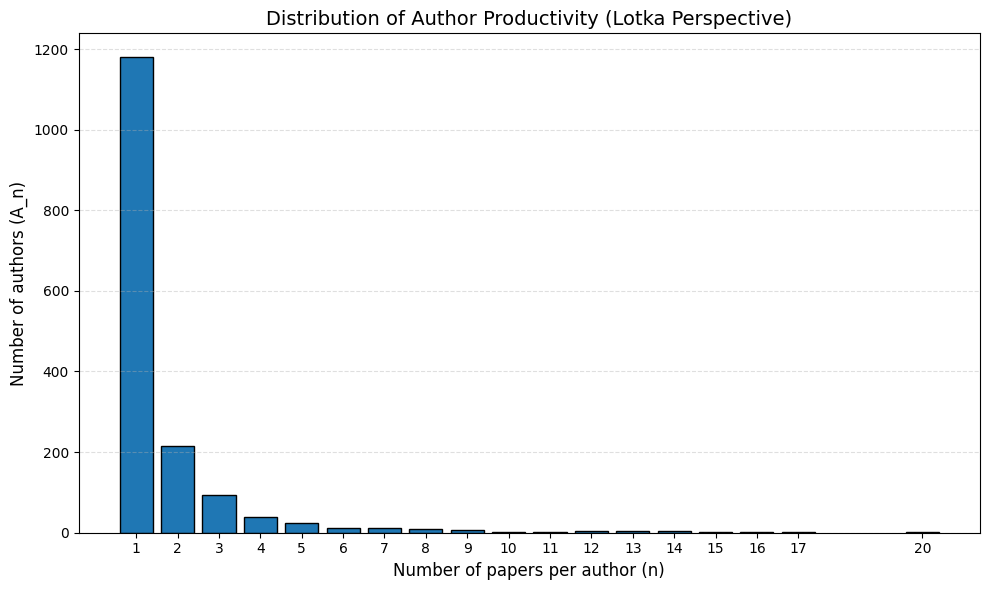


Lotka's Law — Author Productivity Distribution
| n_papers | n_authors | Author_Share_% | Cumulative_Authors | Cumulative_Share_% | Lotka_Theoretical |
| --- | --- | --- | --- | --- | --- |
| 1 | 1180 | 73.29 | 1180 | 73.29 | 1156.4489609367329 |
| 2 | 214 | 13.29 | 1394 | 86.58 | 226.8249113453486 |
| 3 | 93 | 5.78 | 1487 | 92.36 | 87.47166266183264 |
| 4 | 39 | 2.42 | 1526 | 94.78 | 44.489244354675805 |
| 5 | 23 | 1.43 | 1549 | 96.21 | 26.333682534437823 |
| 6 | 12 | 0.75 | 1561 | 96.96 | 17.15661719513264 |
| 7 | 12 | 0.75 | 1573 | 97.7 | 11.942721873840503 |
| 8 | 8 | 0.5 | 1581 | 98.2 | 8.726082384471926 |
| 9 | 6 | 0.37 | 1587 | 98.57 | 6.616194944416603 |
| 10 | 3 | 0.19 | 1590 | 98.76 | 5.165065997752401 |
| 11 | 1 | 0.06 | 1591 | 98.82 | 4.128582532554601 |
| 12 | 5 | 0.31 | 1596 | 99.13 | 3.3650842412620254 |
| 13 | 4 | 0.25 | 1600 | 99.38 | 2.788067168292165 |
| 14 | 4 | 0.25 | 1604 | 99.63 | 2.342435266716649 |
| 15 | 2 | 0.12 | 1606 | 99.75 | 1.9918310907818408 |
| 16 | 2 

In [9]:
import pandas as pd
import os
import ast
import numpy as np
import matplotlib.pyplot as plt

from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ============================================================
# Lotka's Law of Scientific Productivity
# (Author productivity distribution + Lotka plot)
# ============================================================

# -----------------------------
# PARAMETERS (easy to adjust)
# -----------------------------
YEAR_MIN = None     # e.g., 2005 (or None for no lower bound)
YEAR_MAX = None     # e.g., 2025 (or None for no upper bound)
MIN_PAPERS_FOR_FIT = 1   # minimum n for including in log-log fit

# ============================================================
# Load dataset
# ============================================================
df = DATASET()

# ------------------------------------------------------------
# Helper: convert string → Python list safely
# ------------------------------------------------------------
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except (ValueError, SyntaxError):
        return [val] if not pd.isna(val) else []

# Convert authors field to list
df["authors"] = df["authors"].apply(safe_eval)

# Ensure year is numeric (optional filtering)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"])
df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]

if df.empty:
    raise ValueError("No articles available after year filtering for Lotka analysis.")

# ============================================================
# STEP 1 — Build author–article frequency
# ============================================================
# Explode authors so each row = one author–article combination
df_auth = df.explode("authors").dropna(subset=["authors"])

# Normalize author names (optional: strip spaces)
df_auth["authors"] = df_auth["authors"].astype(str).str.strip()

if df_auth.empty:
    raise ValueError("No author data available after exploding 'authors' for Lotka analysis.")

# Count number of articles per author
author_productivity = (
    df_auth.groupby("authors")
    .size()
    .rename("n_papers")
    .reset_index()
)

# ============================================================
# STEP 2 — Distribution: A_n = number of authors with exactly n papers
# ============================================================
lotka_dist = (
    author_productivity["n_papers"]
    .value_counts()
    .sort_index()
    .rename_axis("n_papers")
    .reset_index(name="n_authors")
)

# Total number of authors
total_authors = lotka_dist["n_authors"].sum()

# Add share (%) columns
lotka_dist["Author_Share_%"] = (100 * lotka_dist["n_authors"] / total_authors).round(2)

# Cumulative share (for inspection)
lotka_dist["Cumulative_Authors"] = lotka_dist["n_authors"].cumsum()
lotka_dist["Cumulative_Share_%"] = (100 * lotka_dist["Cumulative_Authors"] / total_authors).round(2)

print("Total unique authors:", total_authors)
print(lotka_dist.head())

# ============================================================
# STEP 3 — Fit Lotka's Law: A_n ≈ A_1 * n^-alpha  (log–log regression)
# ============================================================
# Use only n >= MIN_PAPERS_FOR_FIT
fit_data = lotka_dist[lotka_dist["n_papers"] >= MIN_PAPERS_FOR_FIT].copy()

# Avoid zeros
fit_data = fit_data[fit_data["n_authors"] > 0]

if len(fit_data) < 2:
    raise ValueError("Not enough data points to fit Lotka's Law.")

# log-log transformation
x = np.log(fit_data["n_papers"].values)
y = np.log(fit_data["n_authors"].values)

# Linear regression: y = a + b*x  → A_n = exp(a) * n^b
b, a = np.polyfit(x, y, 1)
alpha_est = -b            # in Lotka's form A_n = A_1 * n^-alpha
A1_est = np.exp(a)        # estimated A_1

print("Estimated Lotka parameters:")
print(f"  A_1 ≈ {A1_est:.3f}")
print(f"  alpha ≈ {alpha_est:.3f}")

# Build theoretical curve for comparison
n_values = lotka_dist["n_papers"].values
lotka_theoretical = A1_est * (n_values ** (-alpha_est))

# Normalize theoretical curve so its sum roughly matches total authors
scale_factor = total_authors / lotka_theoretical.sum()
lotka_theoretical_scaled = lotka_theoretical * scale_factor

# Add to DataFrame for reference
lotka_dist["Lotka_Theoretical"] = lotka_theoretical_scaled

# ============================================================
# PLOT 1 — Lotka Plot (log–log) of empirical vs theoretical
# ============================================================
plt.figure(figsize=(8, 6))

plt.scatter(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    label="Empirical",
    marker="o"
)

plt.plot(
    lotka_dist["n_papers"],
    lotka_dist["Lotka_Theoretical"],
    label=f"Theoretical Lotka fit (alpha ≈ {alpha_est:.2f})"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors with n papers (A_n)", fontsize=12)
plt.title("Lotka's Law of Scientific Productivity (Log–Log Plot)", fontsize=14)
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()

if SAVE_MODE:
    png_file = OUTPUT_DIR / "lotkas_law_loglog_plot.png"
    plt.savefig(png_file, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file)}` saved.")

plt.show()
plt.close()

# ============================================================
# PLOT 2 — Linear-scale bar chart of empirical distribution
# ============================================================
plt.figure(figsize=(10, 6))

plt.bar(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    edgecolor="black"
)

plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors (A_n)", fontsize=12)
plt.title("Distribution of Author Productivity (Lotka Perspective)", fontsize=14)

plt.xticks(lotka_dist["n_papers"])
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

if SAVE_MODE:
    png_file_bar = OUTPUT_DIR / "lotkas_law_productivity_distribution.png"
    plt.savefig(png_file_bar, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file_bar)}` saved.")

plt.show()
plt.close()

# ============================================================
# Export distribution table as markdown
# ============================================================
t = dataframe_to_markdown(
    lotka_dist,
    table_name="Lotka's Law — Author Productivity Distribution"
)


## Supplementary Figure S6 
Bradford distribution of journals publishing ISO 13606/openEHR research. A small core of venues accounts for a substantial proportion of publications, consistent with Bradford’s Law. Journals are ranked in descending order based on the number of publications in the study corpus. The distribution follows Bradford’s Law, with a small core of highly productive journals accounting for a substantial proportion of publications, followed by progressively larger groups of less productive journals. Zone 1 includes three journals contributing 30.82% of articles, Zone 2 includes eight journals contributing 33.56%, and Zone 3 includes 58 journals contributing 35.62%, reflecting increasing dispersion across zones.

**Bradford’s Law with Bradford Zones**

Bradford’s Law of Scattering describes the distribution of relevant literature across scientific journals and is widely used to identify the core publication sources within a research field. According to this law, when journals are ranked in descending order of productivity (i.e., number of articles published on a given topic), they can be divided into groups or “zones” such that each zone contributes approximately the same number of relevant articles, but the number of journals required for each successive zone increases geometrically. Formally, if the first zone contains ( k ) core journals, then the number of journals in the subsequent zones tends to follow the ratio:

$$
1 : b : b^2 : b^3 : \ldots
$$

where $ b $ is Bradford’s multiplier representing the rate at which scattering increases. Bradford’s Law thus provides a quantitative model for assessing journal concentration and dispersion, helping to identify core, related, and peripheral publication outlets within a research domain.

------------------------------------------------------------
Bradford’s Law of Scattering — Results
Total Articles: 534
Zone 1 Journals: 2, Zone 2: 23, Zone 3: 150
Estimated Bradford Multiplier (b): 9.011
------------------------------------------------------------

Bradford Zone Distribution Summary
| Bradford_Zone | Journals | Articles | Article_Share_% |
| --- | --- | --- | --- |
| Zone 1 (Core) | 2 | 159 | 29.78 |
| Zone 2 | 23 | 196 | 36.7 |
| Zone 3 | 150 | 179 | 33.52 |

`bradford_curve.png` saved.


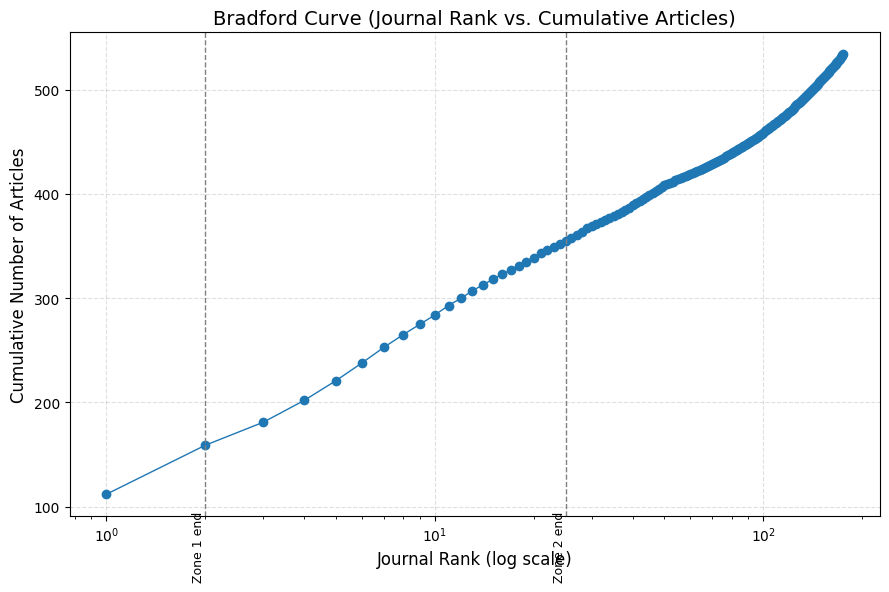

`bradford_lorenz_like_plot.png` saved.


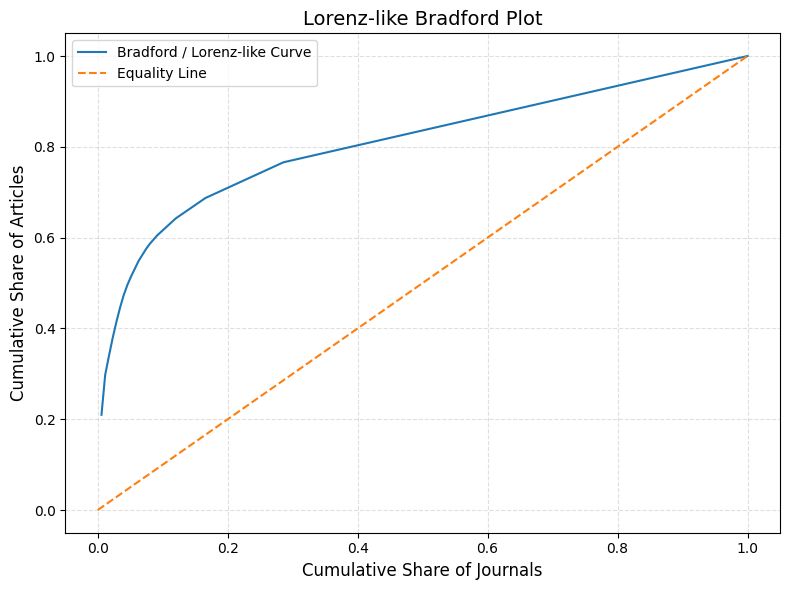


Journals with Bradford Rank, Cumulative Articles, and Zones
| journal_title | Article_Count | Rank | Cumulative_Count | Cumulative_Share | Bradford_Zone | Cum_Journals | Cum_Journals_Share |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Studies in health technology and informatics | 112 | 1 | 112 | 0.20973782771535582 | Zone 1 (Core) | 1 | 0.005714285714285714 |
| Studies in Health Technology and Informatics | 47 | 2 | 159 | 0.29775280898876405 | Zone 1 (Core) | 2 | 0.011428571428571429 |
| BMC Medical Informatics and Decision Making | 22 | 3 | 181 | 0.3389513108614232 | Zone 2 | 3 | 0.017142857142857144 |
| International Journal of Medical Informatics | 21 | 4 | 202 | 0.3782771535580524 | Zone 2 | 4 | 0.022857142857142857 |
| Journal of Biomedical Informatics | 19 | 5 | 221 | 0.41385767790262173 | Zone 2 | 5 | 0.02857142857142857 |
| Procedia Computer Science | 17 | 6 | 238 | 0.44569288389513106 | Zone 2 | 6 | 0.03428571428571429 |
| Methods of Information in Medicine | 15 | 7 

In [10]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_markdown

# ============================================================
# Bradford’s Law with Bradford Zones + Bradford Curve Plot
# ============================================================

# --- Load dataset
df = DATASET()

# ============================================================
# STEP 1 — Count number of articles per journal
# ============================================================
df_journal = (
    df.groupby("journal_title")
      .size()
      .reset_index(name="Article_Count")
      .dropna(subset=["journal_title"])
)

if df_journal.empty:
    raise ValueError("No journal data available for applying Bradford’s Law.")

# Sort journals by productivity (descending)
df_journal = df_journal.sort_values("Article_Count", ascending=False).reset_index(drop=True)

# Add rank (1 = most productive journal)
df_journal["Rank"] = np.arange(1, len(df_journal) + 1)

# ============================================================
# STEP 2 — Compute cumulative distribution of articles
# ============================================================
total_articles = df_journal["Article_Count"].sum()
df_journal["Cumulative_Count"] = df_journal["Article_Count"].cumsum()
df_journal["Cumulative_Share"] = df_journal["Cumulative_Count"] / total_articles

# ============================================================
# STEP 3 — Divide journals into 3 Bradford Zones
# Each zone ≈ 1/3 of total relevant articles
# ============================================================
zone_cut = [1/3, 2/3, 1.0]

def assign_zone(share):
    if share <= zone_cut[0]:
        return "Zone 1 (Core)"
    elif share <= zone_cut[1]:
        return "Zone 2"
    else:
        return "Zone 3"

df_journal["Bradford_Zone"] = df_journal["Cumulative_Share"].apply(assign_zone)

# ============================================================
# STEP 4 — Estimate Bradford Multiplier (b)
# Using ratio of journal counts in each zone
# ============================================================
zone_counts = df_journal["Bradford_Zone"].value_counts().sort_index()
Z1 = zone_counts.get("Zone 1 (Core)", 1)
Z2 = zone_counts.get("Zone 2", 1)
Z3 = zone_counts.get("Zone 3", 1)

b_est1 = Z2 / Z1 if Z1 > 0 else np.nan
b_est2 = Z3 / Z2 if Z2 > 0 else np.nan
b_estimate = np.nanmean([b_est1, b_est2])

print("------------------------------------------------------------")
print("Bradford’s Law of Scattering — Results")
print("Total Articles:", total_articles)
print(f"Zone 1 Journals: {Z1}, Zone 2: {Z2}, Zone 3: {Z3}")
print(f"Estimated Bradford Multiplier (b): {b_estimate:.3f}")
print("------------------------------------------------------------")

# ============================================================
# STEP 5 — Zone Distribution Summary Table
# ============================================================
zone_summary = (
    df_journal.groupby("Bradford_Zone")
    .agg(
        Journals=("journal_title", "nunique"),
        Articles=("Article_Count", "sum")
    )
    .reset_index()
)

zone_summary["Article_Share_%"] = (
    100 * zone_summary["Articles"] / total_articles
).round(2)

# Send summary to markdown helper
t_zone = dataframe_to_markdown(
    zone_summary,
    table_name="Bradford Zone Distribution Summary"
)

# ============================================================
# PLOT 1 — Bradford Curve (Rank vs. Cumulative Articles)
# Classic way: rank on x-axis (log scale), cumulative articles on y-axis
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    df_journal["Rank"],
    df_journal["Cumulative_Count"],
    marker="o",
    linestyle="-",
    linewidth=1
)

plt.xscale("log")  # log-scale for rank
plt.xlabel("Journal Rank (log scale)", fontsize=12)
plt.ylabel("Cumulative Number of Articles", fontsize=12)
plt.title("Bradford Curve (Journal Rank vs. Cumulative Articles)", fontsize=14)

# Optional: vertical lines at zone boundaries (where zones change)
zone1_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 1 (Core)", "Rank"].max()
zone2_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 2", "Rank"].max()

if not np.isnan(zone1_max_rank):
    plt.axvline(zone1_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(zone1_max_rank, plt.ylim()[1]*0.05, "Zone 1 end", rotation=90, va="bottom", ha="right", fontsize=9)

if not np.isnan(zone2_max_rank):
    plt.axvline(zone2_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(zone2_max_rank, plt.ylim()[1]*0.05, "Zone 2 end", rotation=90, va="bottom", ha="right", fontsize=9)

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

if SAVE_MODE:
    png_file_bradford = OUTPUT_DIR / "bradford_curve.png"
    plt.savefig(png_file_bradford, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file_bradford)}` saved.")

plt.show()
plt.close()

# ============================================================
# PLOT 2 — Optional: Lorenz-like Bradford Plot (if you want both)
# (Cumulative share of journals vs. cumulative share of articles)
# ============================================================
df_journal["Cum_Journals"] = df_journal["Rank"]
df_journal["Cum_Journals_Share"] = df_journal["Cum_Journals"] / len(df_journal)

plt.figure(figsize=(8, 6))

plt.plot(
    df_journal["Cum_Journals_Share"],
    df_journal["Cumulative_Share"],
    label="Bradford / Lorenz-like Curve"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Equality Line")

plt.xlabel("Cumulative Share of Journals", fontsize=12)
plt.ylabel("Cumulative Share of Articles", fontsize=12)
plt.title("Lorenz-like Bradford Plot", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

if SAVE_MODE:
    png_file_lorenz = OUTPUT_DIR / "bradford_lorenz_like_plot.png"
    plt.savefig(png_file_lorenz, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file_lorenz)}` saved.")

plt.show()
plt.close()

# ============================================================
# (Optional) Export full journal table with zone and rank info
# ============================================================
t_journals = dataframe_to_markdown(
    df_journal,
    table_name="Journals with Bradford Rank, Cumulative Articles, and Zones"
)

if SAVE_MODE:
    out_file = OUTPUT_DIR / "bradford_journal_details.csv"
    df_journal.to_csv(out_file, index=False)
    print(f"`{out_file.name}` saved.")


## Supplementary Figure S7
Cross-national distribution of thematic categories in ISO 13606/openEHR research. Bars represent the proportion of thematic assignments within each country’s publication corpus.

`stacked_thematic_categories_top15_countries.png` saved.


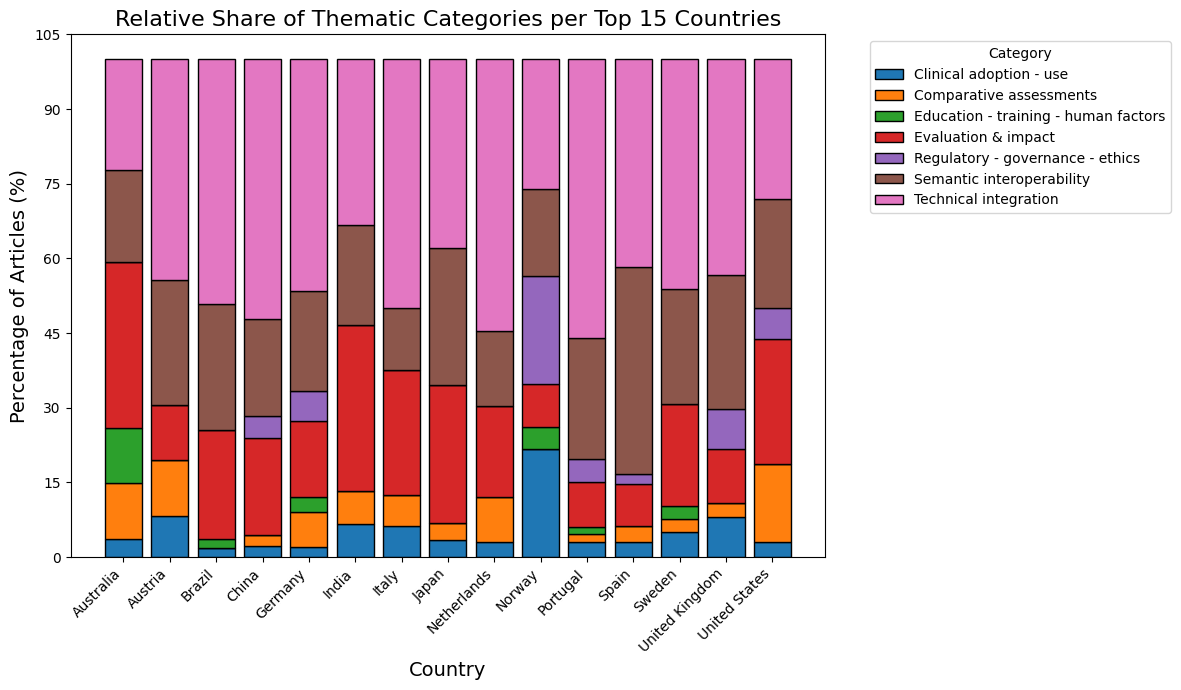


Relative Share of Thematic Categories per Top 15 Countries
| affiliation_integration_country | Clinical adoption - use | Comparative assessments | Education - training - human factors | Evaluation & impact | Regulatory - governance - ethics | Semantic interoperability | Technical integration |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Australia | 3.7037037037037033 | 11.11111111111111 | 11.11111111111111 | 33.33333333333333 | 0.0 | 18.51851851851852 | 22.22222222222222 |
| Austria | 8.333333333333332 | 11.11111111111111 | 0.0 | 11.11111111111111 | 0.0 | 25.0 | 44.44444444444444 |
| Brazil | 1.8181818181818181 | 0.0 | 1.8181818181818181 | 21.818181818181817 | 0.0 | 25.454545454545453 | 49.09090909090909 |
| China | 2.1739130434782608 | 2.1739130434782608 | 0.0 | 19.565217391304348 | 4.3478260869565215 | 19.565217391304348 | 52.17391304347826 |
| Germany | 2.0202020202020203 | 7.07070707070707 | 3.0303030303030303 | 15.151515151515152 | 6.0606060606060606 | 20.2020202020202 | 

In [11]:
import pandas as pd
import os
import ast
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from src.config import OUTPUT_DIR, SAVE_MODE
from src.lib_visualization import dataframe_to_markdown
from src.lib_dataset import DATASET

# ============================================================
# Load dataset
# ============================================================
df = DATASET()

# ------------------------------------------------------------
# Helper to convert string → Python list
# ------------------------------------------------------------
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except (ValueError, SyntaxError):
        return [val] if not pd.isna(val) else []

# Convert list-like fields
df["DEFA_assigned_category_v3"] = df["DEFA_assigned_category_v3"].apply(safe_eval)
df["affiliation_integration_country"] = df["affiliation_integration_country"].apply(safe_eval)

# ------------------------------------------------------------
# Explode countries and categories
# ------------------------------------------------------------
df_exp = (
    df.explode("affiliation_integration_country")
      .explode("DEFA_assigned_category_v3")
      .dropna(subset=["affiliation_integration_country", "DEFA_assigned_category_v3"])
)

# ------------------------------------------------------------
# Count occurrences of (Country, Category)
# ------------------------------------------------------------
country_category_counts = (
    df_exp.groupby(["affiliation_integration_country", "DEFA_assigned_category_v3"])
    .size()
    .reset_index(name="Count")
)

# Determine top 10 countries by total article count
top_countries = (
    country_category_counts.groupby("affiliation_integration_country")["Count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index
)

# Filter to top countries only
df_top = country_category_counts[
    country_category_counts["affiliation_integration_country"].isin(top_countries)
]

# ------------------------------------------------------------
# Pivot: rows = countries, columns = categories
# ------------------------------------------------------------
pivot_df = df_top.pivot_table(
    index="affiliation_integration_country",
    columns="DEFA_assigned_category_v3",
    values="Count",
    aggfunc="sum",
    fill_value=0
)

# ------------------------------------------------------------
# Convert raw counts → relative share within each country (%)
# ------------------------------------------------------------
pivot_pct = pivot_df.div(pivot_df.sum(axis=1), axis=0) * 100
pivot_pct = pivot_pct.sort_index()  # for stable plotting order

# ------------------------------------------------------------
# Plot Stacked Bar Chart
# ------------------------------------------------------------
plt.figure(figsize=(12, 7))

bottom = None
for category in pivot_pct.columns:
    plt.bar(
        pivot_pct.index,
        pivot_pct[category],
        bottom=bottom,
        label=category,
        edgecolor="black"
    )
    bottom = (pivot_pct[category] if bottom is None else bottom + pivot_pct[category])

plt.title("Relative Share of Thematic Categories per Top 15 Countries", fontsize=16)
plt.ylabel("Percentage of Articles (%)", fontsize=14)
plt.xlabel("Country", fontsize=14)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Save figure
if SAVE_MODE:
    png_file = OUTPUT_DIR / "stacked_thematic_categories_top15_countries.png"
    plt.savefig(png_file, dpi=300, bbox_inches="tight")
    print(f"`{os.path.basename(png_file)}` saved.")

plt.show()
plt.close()

# Export summary table
t = dataframe_to_markdown(
    pivot_pct.reset_index(),
    table_name="Relative Share of Thematic Categories per Top 15 Countries"
)


## End